In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ecg = np . array ([0 ,1 ,2 ,4 ,8 ,4 ,2 ,1 ,0 ,1 ,2 ,5 ,9 ,5 ,2 ,1 ,0 ,0 ,3 ,1] , dtype = float )


radio = np . array ([
[0 , 0, 1, 1, 0, 0] ,
[0 , 2, 4, 4, 2, 0] ,
[1 , 4, 8, 8, 4, 1] ,
[1 , 4, 8, 8, 4, 1] ,
[0 , 2, 4, 4, 2, 0] ,
[0 , 0, 1, 1, 0, 0]
], dtype = float )


irm = np . array ([
[[1 ,2 ,1] ,[2 ,4 ,2] ,[1 ,2 ,1]] ,
[[2 ,4 ,2] ,[4 ,8 ,4] ,[2 ,4 ,2]] ,
[[1 ,2 ,1] ,[2 ,4 ,2] ,[1 ,2 ,1]]
], dtype = float )

In [17]:
print("ECG :\n", ecg.shape)

ECG :
 (20,)


In [18]:
def conv1d(signal, kernel, padding=0, stride=1):
    N = len(signal)
    k = len(kernel)

    if padding > 0:
        signal = np.pad(signal, (padding, padding), mode='constant')

    N_pad = len(signal)

    output_size = (N_pad - k)//stride + 1
    output = np.zeros(output_size)

    for i in range(output_size):
        start = i * stride
        end = start + k
        output[i] = np.sum(signal[start:end] * kernel)

    return output



In [19]:
w = np.array([1, -2, 1] , dtype=float)
conv_ecg_config1 = conv1d(ecg, w, padding=0, stride=1)
conv_ecg_config2 = conv1d(ecg, w, padding=1, stride=1)
conv_ecg_config3 = conv1d(ecg, w, padding=0, stride=2)

print("Convolution ECG Config 1 (padding=0, stride=1):\n", conv_ecg_config1)
print("Taille de signal après convolution (Config 1):", len(conv_ecg_config1))
print("Convolution ECG Config 2 (padding=1, stride=1):\n", conv_ecg_config2)
print("Taille de signal après convolution (Config 2):", len(conv_ecg_config2))
print("Convolution ECG Config 3 (padding=0, stride=2):\n", conv_ecg_config3)
print("Taille de signal après convolution (Config 3):", len(conv_ecg_config3))

Convolution ECG Config 1 (padding=0, stride=1):
 [ 0.  1.  2. -8.  2.  1.  0.  2.  0.  2.  1. -8.  1.  2.  0.  1.  3. -5.]
Taille de signal après convolution (Config 1): 18
Convolution ECG Config 2 (padding=1, stride=1):
 [ 1.  0.  1.  2. -8.  2.  1.  0.  2.  0.  2.  1. -8.  1.  2.  0.  1.  3.
 -5.  1.]
Taille de signal après convolution (Config 2): 20
Convolution ECG Config 3 (padding=0, stride=2):
 [0. 2. 2. 0. 0. 1. 1. 0. 3.]
Taille de signal après convolution (Config 3): 9


In [23]:
def detect_arythmie(conv_output, threshold=3):
    conv_output = np.asarray(conv_output, dtype=float)
    return np.where(np.abs(conv_output) > threshold)[0]

In [ ]:
padding, stride = 0, 1
y = conv1d(ecg, w, padding=padding, stride=stride)

threshold = 3.0
anom_idx_y = detect_arythmie(y, threshold=threshold)

k = len(w)
center_offset = k // 2 
anom_idx_ecg = anom_idx_y * stride - padding + center_offset

anom_idx_ecg = anom_idx_ecg[(anom_idx_ecg >= 0) & (anom_idx_ecg < len(ecg))].astype(int)


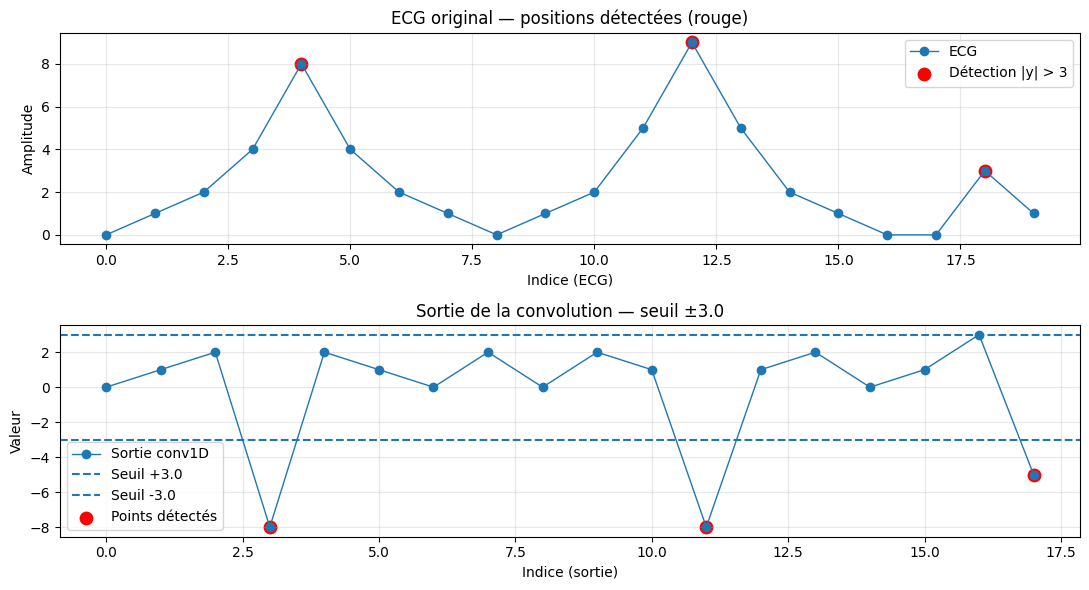

In [ ]:
t_ecg = np.arange(len(ecg))
t_y = np.arange(len(y))

fig, ax = plt.subplots(2, 1, figsize=(11, 6))

# (a) ECG original + points détectés en rouge
ax[0].plot(t_ecg, ecg, marker='o', linewidth=1, label="ECG")
if len(anom_idx_ecg) > 0:
    ax[0].scatter(anom_idx_ecg, ecg[anom_idx_ecg], color='red', s=80, label="Détection |y| > 3")
ax[0].set_title("ECG original — positions détectées (rouge)")
ax[0].set_xlabel("Indice (ECG)")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True, alpha=0.3)
ax[0].legend()

# (b) Sortie convolution + seuil
ax[1].plot(t_y, y, marker='o', linewidth=1, label="Sortie conv1D")
ax[1].axhline(threshold, linestyle='--', label="Seuil +3.0")
ax[1].axhline(-threshold, linestyle='--', label="Seuil -3.0")
if len(anom_idx_y) > 0:
    ax[1].scatter(anom_idx_y, y[anom_idx_y], color='red', s=80, label="Points détectés")
ax[1].set_title("Sortie de la convolution — seuil ±3.0")
ax[1].set_xlabel("Indice (sortie)")
ax[1].set_ylabel("Valeur")
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig("mission1_ecg.png", dpi=200)
plt.show()

In [ ]:
# Commentaire (Q3) :
# Le détecteur basé sur |y| > 3 (y = sortie conv1D) détecte seulement certains points
# dans la zone anormale 9→18 (ex. autour des pics), mais pas toute la plage 9→18.
# Il peut aussi détecter un point dans 0→8 (faux positif), car le filtre [1,-2,1]
# met en évidence les changements brusques (≈ dérivée seconde) et non l’amplitude brute.

In [26]:
ecg_matin = np.array([0, 1, 2, 4, 8, 4, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=float)
ecg_soir  = np.array([0, 0, 0, 0, 0, 0, 1, 2, 4, 8, 4, 2, 1, 0, 0, 0, 0, 0, 0, 0], dtype=float)

w_shift = np.array([1, -1], dtype=float)

y_matin = conv1d(ecg_matin, w_shift, padding=0, stride=1)
y_soir  = conv1d(ecg_soir,  w_shift, padding=0, stride=1)

print("y_matin =", y_matin)
print("y_soir  =", y_soir)



y_matin = [-1. -1. -2. -4.  4.  2.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.]
y_soir  = [ 0.  0.  0.  0.  0. -1. -1. -2. -4.  4.  2.  1.  1.  0.  0.  0.  0.  0.
  0.]


Sorties identiques (valeurs + positions) ? -> False
Pic (matin) à l'indice : 3 valeur : -4.0
Pic (soir)  à l'indice : 8 valeur : -4.0
Décalage estimé (soir - matin) à partir des pics = 5
y_soir ≈ y_matin décalé ? -> True


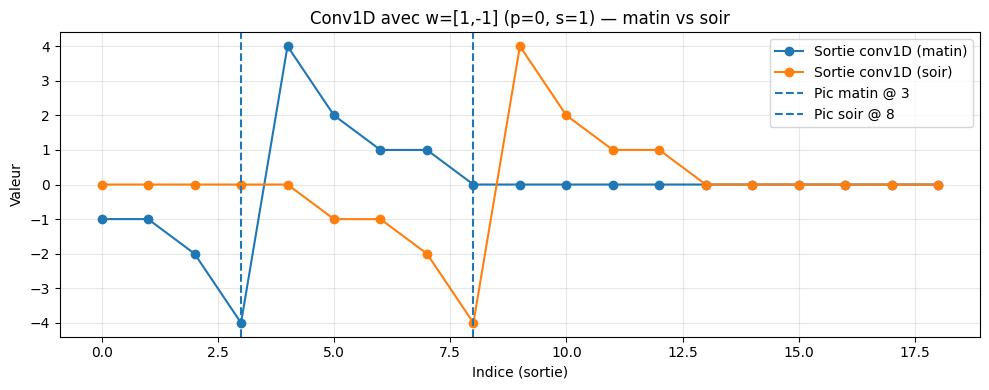

In [28]:
same_values = np.allclose(y_matin, y_soir)
print("Sorties identiques (valeurs + positions) ? ->", same_values)

peak_matin = int(np.argmax(np.abs(y_matin)))
peak_soir  = int(np.argmax(np.abs(y_soir)))
print("Pic (matin) à l'indice :", peak_matin, "valeur :", y_matin[peak_matin])
print("Pic (soir)  à l'indice :", peak_soir,  "valeur :", y_soir[peak_soir])

shift_estime = peak_soir - peak_matin
print("Décalage estimé (soir - matin) à partir des pics =", shift_estime)

# 3) Vérifier si c'est la même forme mais juste décalée (équivariance)
# On teste si y_soir ≈ y_matin décalé de shift_estime
def shift_right(arr, s):
    out = np.zeros_like(arr)
    if s >= 0:
        out[s:] = arr[:len(arr)-s]
    else:
        s = -s
        out[:len(arr)-s] = arr[s:]
    return out

y_matin_shifted = shift_right(y_matin, shift_estime)
print("y_soir ≈ y_matin décalé ? ->", np.allclose(y_soir, y_matin_shifted))

# 4) Figure : les deux sorties sur le même graphe
plt.figure(figsize=(10,4))
plt.plot(y_matin, marker='o', label="Sortie conv1D (matin)")
plt.plot(y_soir,  marker='o', label="Sortie conv1D (soir)")
plt.axvline(peak_matin, linestyle='--', label=f"Pic matin @ {peak_matin}")
plt.axvline(peak_soir,  linestyle='--', label=f"Pic soir @ {peak_soir}")
plt.title("Conv1D avec w=[1,-1] (p=0, s=1) — matin vs soir")
plt.xlabel("Indice (sortie)")
plt.ylabel("Valeur")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("conv1d_matin_soir.png", dpi=200)
plt.show()

In [29]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=float)


In [30]:
def conv2d(image, kernel, padding=0, stride=1):
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if padding > 0:
        image = np.pad(image, ((padding, padding), (padding, padding)), mode="constant")

    H, W = image.shape
    kH, kW = kernel.shape

    outH = (H - kH) // stride + 1
    outW = (W - kW) // stride + 1
    out = np.zeros((outH, outW), dtype=float)

    for i in range(outH):
        for j in range(outW):
            r = i * stride
            c = j * stride
            patch = image[r:r+kH, c:c+kW]
            out[i, j] = np.sum(patch * kernel)  # corrélation (pas de flip)

    return out

In [31]:
O_x0 = conv2d(radio, sobel_x, padding=0, stride=1)
print("Sobel-X sans padding (4x4):\n", O_x0)

Sobel-X sans padding (4x4):
 [[ 16.   9.  -9. -16.]
 [ 25.  14. -14. -25.]
 [ 25.  14. -14. -25.]
 [ 16.   9.  -9. -16.]]


In [ ]:
# --- Calcul manuel demandé ---
# O[0,0] : patch = [[0,0,1],[0,2,4],[1,4,8]]
# kernel = [[-1,0,1],[-2,0,2],[-1,0,1]]
# O[0,0] = 0*(-1)+0*0+1*1 + 0*(-2)+2*0+4*2 + 1*(-1)+4*0+8*1
#        = 0+0+1 + 0+0+8 + (-1)+0+8 = 16
#
# O[1,1] : patch = [[2,4,4],[4,8,8],[4,8,8]]
# O[1,1] = 2*(-1)+4*0+4*1 + 4*(-2)+8*0+8*2 + 4*(-1)+8*0+8*1
#        = -2+0+4 + -8+0+16 + -4+0+8 = 14

In [32]:
O_x1 = conv2d(radio, sobel_x, padding=1, stride=1)
print("\nSobel-X avec padding=1 (6x6):\n", O_x1)


Sobel-X avec padding=1 (6x6):
 [[  2.   6.   4.  -4.  -6.  -2.]
 [  8.  16.   9.  -9. -16.  -8.]
 [ 14.  25.  14. -14. -25. -14.]
 [ 14.  25.  14. -14. -25. -14.]
 [  8.  16.   9.  -9. -16.  -8.]
 [  2.   6.   4.  -4.  -6.  -2.]]


In [33]:
corners_no_pad = (O_x0[0,0], O_x0[0,-1], O_x0[-1,0], O_x0[-1,-1])
corners_pad1   = (O_x1[0,0], O_x1[0,-1], O_x1[-1,0], O_x1[-1,-1])

print("\nCoins sans padding (TL, TR, BL, BR):", corners_no_pad)
print("Coins avec padding=1 (TL, TR, BL, BR):", corners_pad1)


Coins sans padding (TL, TR, BL, BR): (np.float64(16.0), np.float64(-16.0), np.float64(16.0), np.float64(-16.0))
Coins avec padding=1 (TL, TR, BL, BR): (np.float64(2.0), np.float64(-2.0), np.float64(2.0), np.float64(-2.0))



Sobel-Y sans padding (4x4):
 [[ 16.  25.  25.  16.]
 [  9.  14.  14.   9.]
 [ -9. -14. -14.  -9.]
 [-16. -25. -25. -16.]]

Gradient combiné G (4x4):
 [[22.627417   26.57066051 26.57066051 22.627417  ]
 [26.57066051 19.79898987 19.79898987 26.57066051]
 [26.57066051 19.79898987 19.79898987 26.57066051]
 [22.627417   26.57066051 26.57066051 22.627417  ]]


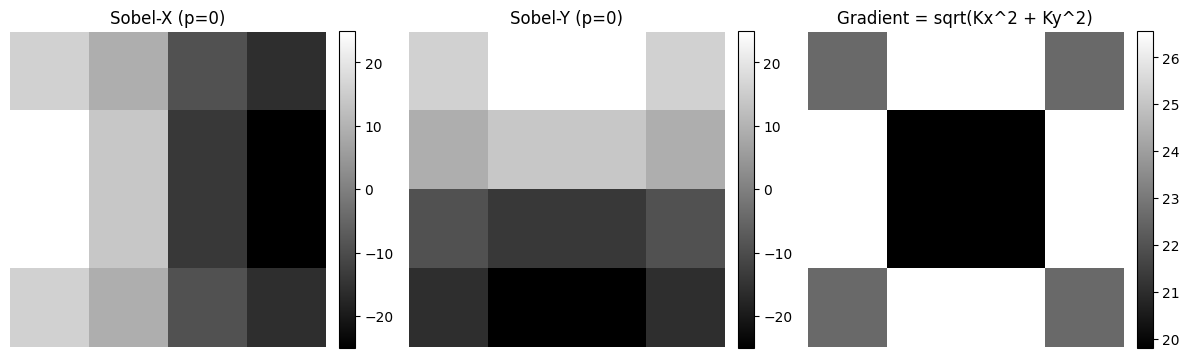

In [35]:
# Question 6(c) — Sobel-Y sans padding + Gradient combiné + heatmaps


O_y0 = conv2d(radio, sobel_y, padding=0, stride=1)
G = np.sqrt(O_x0**2 + O_y0**2)

print("\nSobel-Y sans padding (4x4):\n", O_y0)
print("\nGradient combiné G (4x4):\n", G)

# Heatmaps sur une même figure
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

im0 = ax[0].imshow(O_x0, cmap="gray")
ax[0].set_title("Sobel-X (p=0)")
ax[0].axis("off")
plt.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04)

im1 = ax[1].imshow(O_y0, cmap="gray")
ax[1].set_title("Sobel-Y (p=0)")
ax[1].axis("off")
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

im2 = ax[2].imshow(G, cmap="gray")
ax[2].set_title("Gradient = sqrt(Kx^2 + Ky^2)")
ax[2].axis("off")
plt.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("mission2_sobel_gradient.png", dpi=200)
plt.show()

In [36]:
avg3 = np.ones((3,3), dtype=float) / 9.0
def conv2d(image, kernel, padding=0, stride=1):
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if padding > 0:
        image = np.pad(image, ((padding, padding), (padding, padding)), mode="constant")

    H, W = image.shape
    kH, kW = kernel.shape

    outH = (H - kH) // stride + 1
    outW = (W - kW) // stride + 1
    out = np.zeros((outH, outW), dtype=float)

    for i in range(outH):
        for j in range(outW):
            r = i * stride
            c = j * stride
            patch = image[r:r+kH, c:c+kW]
            out[i, j] = np.sum(patch * kernel)

    return out

In [37]:
def maxpool2d(x, pool_size=2, stride=2):
    x = np.asarray(x, dtype=float)
    H, W = x.shape
    outH = (H - pool_size) // stride + 1
    outW = (W - pool_size) // stride + 1
    out = np.zeros((outH, outW), dtype=float)

    for i in range(outH):
        for j in range(outW):
            r = i * stride
            c = j * stride
            window = x[r:r+pool_size, c:c+pool_size]
            out[i, j] = np.max(window)
    return out

def avgpool2d(x, pool_size=2, stride=2):
    x = np.asarray(x, dtype=float)
    H, W = x.shape
    outH = (H - pool_size) // stride + 1
    outW = (W - pool_size) // stride + 1
    out = np.zeros((outH, outW), dtype=float)

    for i in range(outH):
        for j in range(outW):
            r = i * stride
            c = j * stride
            window = x[r:r+pool_size, c:c+pool_size]
            out[i, j] = np.mean(window)
    return out

def global_avg_pool2d(x):
    x = np.asarray(x, dtype=float)
    return np.mean(x)

In [38]:
# 7(a) Moyennage puis Sobel-X (sans padding à chaque étape)


smooth = conv2d(radio, avg3, padding=0, stride=1)        # 6x6 -> 4x4
edges_after_smooth = conv2d(smooth, sobel_x, padding=0, stride=1)  # 4x4 -> 2x2

print("Taille radio:", radio.shape)
print("Après moyennage:", smooth.shape)
print("Après Sobel-X:", edges_after_smooth.shape)

Taille radio: (6, 6)
Après moyennage: (4, 4)
Après Sobel-X: (2, 2)


In [39]:
# 7(b) Pooling sur Sobel-X sans padding (sortie de Q6)


Ox = conv2d(radio, sobel_x, padding=0, stride=1)  # 4x4
mp = maxpool2d(Ox, pool_size=2, stride=2)
ap = avgpool2d(Ox, pool_size=2, stride=2)

print("\nSobel-X (p=0) =\n", Ox)
print("\nMaxPool 2x2 s=2 -> shape", mp.shape, "\n", mp)
print("\nAvgPool 2x2 s=2 -> shape", ap.shape, "\n", ap)


Sobel-X (p=0) =
 [[ 16.   9.  -9. -16.]
 [ 25.  14. -14. -25.]
 [ 25.  14. -14. -25.]
 [ 16.   9.  -9. -16.]]

MaxPool 2x2 s=2 -> shape (2, 2) 
 [[25. -9.]
 [25. -9.]]

AvgPool 2x2 s=2 -> shape (2, 2) 
 [[ 16. -16.]
 [ 16. -16.]]


In [40]:
# 7(c) Global Average Pooling + comparaison


gap = global_avg_pool2d(Ox)
print("\nGlobal Average Pooling (sur Sobel-X) =", gap)


Global Average Pooling (sur Sobel-X) = 0.0


In [41]:
radio_A = np.array([
    [0, 0, 1, 1, 0, 0],
    [0, 2, 4, 4, 2, 0],
    [1, 4, 8, 8, 4, 1],
    [1, 4, 8, 8, 4, 1],
    [0, 2, 4, 4, 2, 0],
    [0, 0, 1, 1, 0, 0]
], dtype=float)

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=float)

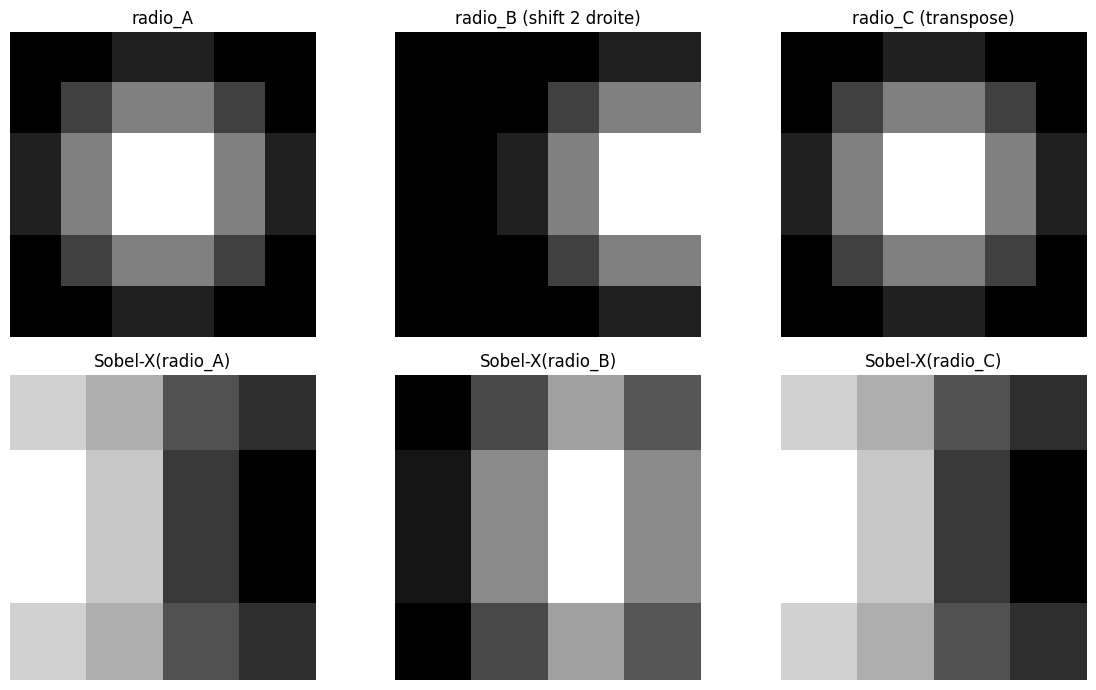

In [45]:
# 8(a) Construire radio_B (shift droite de 2, padding à gauche)


shift = 2
radio_B = np.zeros_like(radio_A)
radio_B[:, shift:] = radio_A[:, :-shift] 

radio_C = radio_A.T

OA = conv2d(radio_A, sobel_x, padding=0, stride=1)
OB = conv2d(radio_B, sobel_x, padding=0, stride=1)
OCx = conv2d(radio_C, sobel_x, padding=0, stride=1) 
OCy = conv2d(radio_C, sobel_y, padding=0, stride=1)  

fig, ax = plt.subplots(2, 3, figsize=(12, 7))

ax[0,0].imshow(radio_A, cmap="gray"); ax[0,0].set_title("radio_A")
ax[0,1].imshow(radio_B, cmap="gray"); ax[0,1].set_title("radio_B (shift 2 droite)")
ax[0,2].imshow(radio_C, cmap="gray"); ax[0,2].set_title("radio_C (transpose)")
for j in range(3): ax[0,j].axis("off")

ax[1,0].imshow(OA, cmap="gray"); ax[1,0].set_title("Sobel-X(radio_A)")
ax[1,1].imshow(OB, cmap="gray"); ax[1,1].set_title("Sobel-X(radio_B)")
ax[1,2].imshow(OCx, cmap="gray"); ax[1,2].set_title("Sobel-X(radio_C)")
for j in range(3): ax[1,j].axis("off")

plt.tight_layout()
plt.savefig("mission2_q8.png", dpi=200)
plt.show()

In [43]:
# 8(b) Comparaison OA vs OB


print("OA == OB exactement ? ->", np.allclose(OA, OB))


OB_expected = np.zeros_like(OA)
OB_expected[:, shift:] = OA[:, :-shift]

print("OB ≈ OA décalé de 2 colonnes ? ->", np.allclose(OB, OB_expected))


OA == OB exactement ? -> False
OB ≈ OA décalé de 2 colonnes ? -> False


In [44]:
# 8(c) Relation entre Sobel-X(A) et Sobel-Y(C)


print("OA ≈ (Sobel-Y(radio_C))^T ? ->", np.allclose(OA, OCy.T))

gmp_A = np.max(OA)
gmp_B = np.max(OB)
gmp_Cy = np.max(OCy)

print("GMP Sobel-X(A) =", gmp_A)
print("GMP Sobel-X(B) =", gmp_B)
print("GMP Sobel-Y(C) =", gmp_Cy)

OA ≈ (Sobel-Y(radio_C))^T ? -> True
GMP Sobel-X(A) = 25.0
GMP Sobel-X(B) = 25.0
GMP Sobel-Y(C) = 25.0


In [46]:
irm = np.array([
    [[1,2,1],[2,4,2],[1,2,1]],
    [[2,4,2],[4,8,4],[2,4,2]],
    [[1,2,1],[2,4,2],[1,2,1]]
], dtype=float)

W = np.array([
    [[1,0],[0,1]],  
    [[0,1],[1,0]]   
], dtype=float)


In [47]:
def conv3d(volume, kernel, padding=0, stride=1):
    volume = np.asarray(volume, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if padding > 0:
        volume = np.pad(
            volume,
            ((padding, padding), (padding, padding), (padding, padding)),
            mode="constant"
        )

    D, H, Wv = volume.shape
    kD, kH, kW = kernel.shape

    outD = (D - kD) // stride + 1
    outH = (H - kH) // stride + 1
    outW = (Wv - kW) // stride + 1

    out = np.zeros((outD, outH, outW), dtype=float)

    for d in range(outD):
        for i in range(outH):
            for j in range(outW):
                ds = d * stride
                hs = i * stride
                ws = j * stride
                patch = volume[ds:ds+kD, hs:hs+kH, ws:ws+kW]
                out[d, i, j] = np.sum(patch * kernel)

    return out

In [48]:
Y = conv3d(irm, W, padding=0, stride=1)
print("Sortie Y (shape =", Y.shape, "):\n", Y)

Sortie Y (shape = (2, 2, 2) ):
 [[[13. 14.]
  [14. 13.]]

 [[14. 13.]
  [13. 14.]]]


In [49]:
print("\nVérif Y[0,0,0] =", Y[0,0,0], "(attendu 13)")



Vérif Y[0,0,0] = 13.0 (attendu 13)


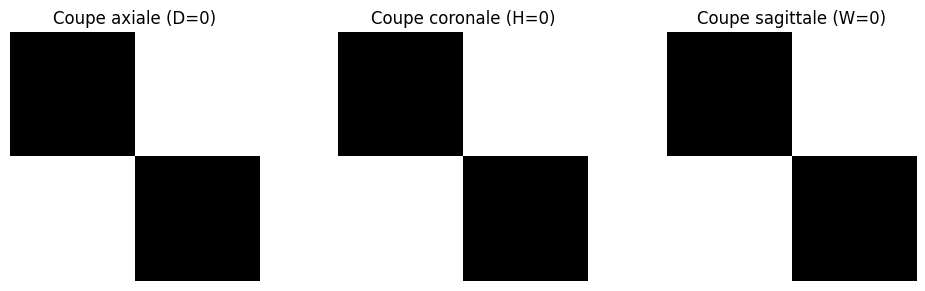

In [51]:
slice_axial   = Y[0, :, :]  
slice_coronal = Y[:, 0, :]   
slice_sagittal= Y[:, :, 0]   

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(slice_axial, cmap="gray")
ax[0].set_title("Coupe axiale (D=0)")
ax[0].axis("off")

ax[1].imshow(slice_coronal, cmap="gray")
ax[1].set_title("Coupe coronale (H=0)")
ax[1].axis("off")

ax[2].imshow(slice_sagittal, cmap="gray")
ax[2].set_title("Coupe sagittale (W=0)")
ax[2].axis("off")

plt.tight_layout()
plt.savefig("mission3_coupes_Y.png", dpi=200)
plt.show()

In [52]:
def relu(x):
    return np.maximum(0, x)

def maxpool3d(volume, pool_size=2, stride=1):
    D, H, W = volume.shape
    outD = (D - pool_size) // stride + 1
    outH = (H - pool_size) // stride + 1
    outW = (W - pool_size) // stride + 1
    out = np.zeros((outD, outH, outW), dtype=float)

    for d in range(outD):
        for i in range(outH):
            for j in range(outW):
                ds, hs, ws = d*stride, i*stride, j*stride
                window = volume[ds:ds+pool_size, hs:hs+pool_size, ws:ws+pool_size]
                out[d, i, j] = np.max(window)
    return out

In [53]:
print("irm shape:", irm.shape)

Y = conv3d(irm, W, padding=0, stride=1)
print("Après Conv3D shape:", Y.shape)
print("Y:\n", Y)

Y_relu = relu(Y)
print("Après ReLU shape:", Y_relu.shape)

Y_pool = maxpool3d(Y_relu, pool_size=2, stride=1)
print("Après MaxPool3D shape:", Y_pool.shape)
print("Y_pool:\n", Y_pool)

irm shape: (3, 3, 3)
Après Conv3D shape: (2, 2, 2)
Y:
 [[[13. 14.]
  [14. 13.]]

 [[14. 13.]
  [13. 14.]]]
Après ReLU shape: (2, 2, 2)
Après MaxPool3D shape: (1, 1, 1)
Y_pool:
 [[[14.]]]
